# Peldaño 3: control distribuido de la ecuación del calor (Manzoni–Quarteroni–Salsa 2021, §8.3) con RBF-FD + CG

**Objetivo.** Reproducir con nuestras herramientas (RBF-FD, adjunto discreto, gradiente conjugado) el ejemplo
transitorio del libro y **comparar con sus Tablas 8.2–8.3 y Figs. 8.1–8.3** (pp. 270–273 del libro; en el PDF,
páginas 281–284). Es el peldaño 3 de la escalera del notebook `caso_base_manzoni_graetz`: lo nuevo es el
**tiempo** (Crank–Nicolson, adjunto hacia atrás, producto escalar en $L^2(Q_T)$) y la **observación final**.

El código está en `calor_nucleo.py` (discretizaciones y optimizador) y `calor_benchmark.py` (referencia y
benchmark), como en Graetz.

## 1. El problema del libro

$\Omega=(0,1)^2$, $T=1$, $Q_T=\Omega\times(0,T)$:
$$
y_t-\Delta y=u\ \text{en } Q_T,\qquad y=0\ \text{en } \partial\Omega\times(0,T),\qquad y(\cdot,0)=0 .
$$
* **Caso 1** (observación distribuida): $\ \tilde J=\frac12\int_{Q_T}|y-y_d|^2+\frac\beta2\int_{Q_T}u^2$,
  $\ y_d=-64\,t\,e^{-|x-c|^2}\chi_{\text{cruz}}$.
* **Caso 2** (observación final): $\ \tilde J=\frac12\int_\Omega|y(T)-z_d|^2+\frac\beta2\int_{Q_T}u^2$,
  $\ z_d=-x_1\,e^{-|x-c|^2}\chi_{\text{cruz}}$.

con $c=(0.5,0.5)$ y cruz $=\{x_1\in(0.4,0.6)\ \text{ó}\ x_2\in(0.4,0.6)\}$: **blancos discontinuos**.

**Libro:** FEM $\mathbb P_1$ (malla no estructurada), Crank–Nicolson, enfoque OtD, BFGS con
$|\nabla J_h|_\infty<10^{-12}$; malla (i) 712 vértices y $\Delta t=0.05$, malla (ii) 1921 vértices y $\Delta t=0.01$.

| | $\beta=10^{-2}$ | $10^{-3}$ | $10^{-4}$ |
|---|---|---|---|
| Tabla 8.2 (caso 1), malla (i) | 147.6619 (36 it) | 91.9129 (63) | 55.4118 (176) |
| Tabla 8.2 (caso 1), malla (ii) | 159.5637 (46) | 104.9392 (82) | 67.2146 (206) |
| Tabla 8.3 (caso 2), malla (i) | 0.018837 (64) | 0.0074174 (153) | 0.0019042 (318) |
| Tabla 8.3 (caso 2), malla (ii) | 0.022603 (66) | 0.012369 (151) | 0.0050182 (308) |

Una señal que conviene notar antes de calcular nada: **el libro cambia mucho entre sus dos mallas** (8 % a 21 % en
el caso 1 y hasta 2.6× en el caso 2), así que sus valores no están convergidos en la malla.

In [1]:
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import calor_nucleo as C
import calor_benchmark as CB

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

## 2. Discretización (discretizar y luego optimizar)

* **Espacio:** RBF-FD en retícula uniforme (PHS $r^3$, grado 3, 30 vecinos, los mismos pesos que en Graetz), Dirichlet
  fuerte; aquí no hay fronteras de Neumann, así que no hacen falta nodos fantasma. Referencia: FEM $\mathbb P_1$
  propio (masa consistente). Retículas **alineadas con la cruz** ($n$ múltiplo de 5).
* **Tiempo:** esquema $\theta$ con $\theta=\tfrac12$ (Crank–Nicolson, como el libro):
  $L\,y^{n+1}=R\,y^n+\Delta t_n B\,(\theta u^{n+1}+(1-\theta)u^n)$, $L=M+\theta\Delta t_n A$, $R=M-(1-\theta)\Delta t_n A$.
  El control es nodal en cada nivel $t_0,\dots,t_{N_t}$ (como el libro: $N_u$ = todos los vértices).
* **Funcional:** trapecio en el tiempo (ec. 8.12 del libro). En el espacio hay dos lecturas:
  **blanco exacto** ($\int y_d\varphi_i$ y $\int y_d^2$ integrados con cuadratura de grado 5, nuestra referencia)
  o **blanco nodal** ($Y_d$ = interpolante nodal, ec. 8.12 literal, $(Y-Y_d)^\top M (Y-Y_d)$).
* **Adjunto discreto** (exacto para $J_h$): $L_{N_t-1}^\top\lambda^{N_t}=g_{N_t}$,
  $L_{n-1}^\top\lambda^n=g_n+R_n^\top\lambda^{n+1}$, y
  $\partial J_h/\partial u^m=\beta w_m M u^m+B^\top(\theta\Delta t_{m-1}\lambda^m+(1-\theta)\Delta t_m\lambda^{m+1})$.
* **CG** precondicionado con el producto $L^2(Q_T)$ discreto ($w_n M$): cada iteración = un barrido hacia adelante +
  uno hacia atrás.

### 2.1 Test de Taylor (orden 2 ⇒ gradiente exacto)

In [2]:
rng = np.random.default_rng(0)
for D in (C.FEM2, C.RBF2):
    d = D(20)
    for case in (1, 2):
        o = C.HeatOCP(d, case, 1e-3, None, t=CB.tgrid(case, 20))
        U = rng.standard_normal((o.nt + 1, d.N)); dU = rng.standard_normal(U.shape)
        J0, g = o.J(U), o.grad(U)
        r = np.array([abs(o.J(U + e * dU) - J0 - e * np.sum(g * dU)) for e in 10.0 ** -np.arange(1, 6)])
        print(f"{D.__name__} caso {case}: tasas {np.round(np.log10(r[:-1] / r[1:]), 2)}")

FEM2 caso 1: tasas [2.   2.   2.01 1.81]
FEM2 caso 2: tasas [2. 2. 2. 2.]


RBF2 caso 1: tasas [2.   2.   2.   1.88]


RBF2 caso 2: tasas [2. 2. 2. 2.]


## 3. ¿Es el mismo problema? Comparación con las Figs. 8.1–8.2

Antes de comparar números de $J$, comparamos **las soluciones**: las escalas de color de las figuras del libro dan
los rangos del estado y del control óptimos (caso 1, malla (ii), $\beta=10^{-3}$ y $10^{-4}$).

β=1e-03: estado ∈ [-34.7, 0.0]   control ∈ [-810, 31]   (14 it CG)


β=1e-04: estado ∈ [-55.3, 0.0]   control ∈ [-1900, 956]   (28 it CG)
libro β=1e-3: estado [-34, 0], control [-820, 8.3];  β=1e-4: estado [-54, 0], control [-1900, 900]


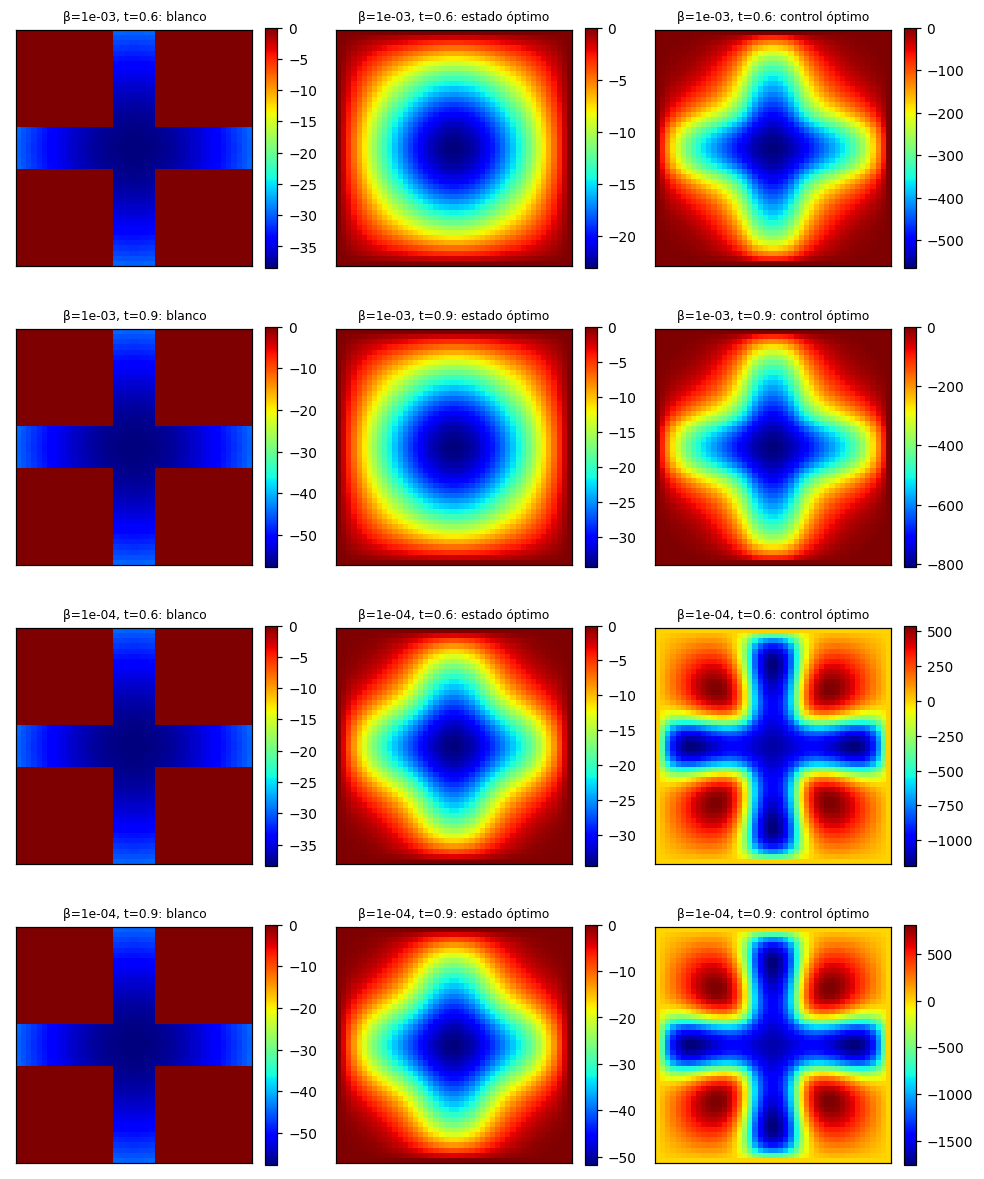

In [3]:
d = C.FEM2(45)
sol = {}
for beta in (1e-3, 1e-4):
    o, U, it = CB.solve(d, 1, beta, C.time_grid(100))
    Y = o.forward(U)
    sol[beta] = (o, U, Y)
    print(f"β={beta:.0e}: estado ∈ [{Y.min():.1f}, {Y.max():.1f}]   control ∈ [{U.min():.0f}, {U.max():.0f}]   ({it} it CG)")
print("libro β=1e-3: estado [-34, 0], control [-820, 8.3];  β=1e-4: estado [-54, 0], control [-1900, 900]")

fig, axs = plt.subplots(4, 3, figsize=(9, 11))
ext = (0, 1, 0, 1)
for r, (beta, tk) in enumerate([(1e-3, 0.6), (1e-3, 0.9), (1e-4, 0.6), (1e-4, 0.9)]):
    o, U, Y = sol[beta]
    k = int(np.argmin(np.abs(o.t - tk)))
    m = d.n + 1
    yd = -64 * o.t[k] * C.profile(d.P, 1)
    for a, (v, ttl) in zip(axs[r], [(yd, "blanco"), (Y[k], "estado óptimo"), (U[k], "control óptimo")]):
        im = a.imshow(v.reshape(m, m).T, origin="lower", extent=ext, cmap="jet")
        plt.colorbar(im, ax=a, fraction=0.046)
        a.set_title(f"β={beta:.0e}, t={o.t[k]:.1f}: {ttl}", fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

Los rangos coinciden con los del libro (estado $[-34.8,0]$ vs $[-34,0]$; control $[-812,31]$ vs $[-820,8.3]$ para
$\beta=10^{-3}$; $[-55.5,0]$ vs $[-54,0]$ y $[-1914,947]$ vs $[-1900,900]$ para $\beta=10^{-4}$) y las formas también
(estado redondeado que no alcanza la cruz para $\beta=10^{-3}$, rombo para $10^{-4}$, control en cruz con lóbulos
positivos en las esquinas). **Es el mismo problema y la misma solución.**

## 4. Los valores de $J$: por qué difieren y cuándo coinciden

Barrido de mallas con las dos lecturas del funcional (caso 1, $\Delta t=0.01$):

In [4]:
print(f"{'n':>4s} {'N':>6s} | {'nodal β=1e-2':>12s} {'1e-3':>9s} {'1e-4':>9s} | {'exacto β=1e-2':>13s} {'1e-3':>9s} {'1e-4':>9s}")
for n in (10, 20, 25, 45, 80):
    dd = C.FEM2(n); row = []
    for exact in (False, True):
        for beta in CB.BETAS:
            o, U, _ = CB.solve(dd, 1, beta, C.time_grid(100), exact=exact)
            row.append(o.J(U))
    print(f"{n:4d} {dd.N:6d} | {row[0]:12.5g} {row[1]:9.5g} {row[2]:9.5g} | {row[3]:13.5g} {row[4]:9.5g} {row[5]:9.5g}")
print("libro (ii), 1921 vértices:        159.56    104.94    67.215")

   n      N | nodal β=1e-2      1e-3      1e-4 | exacto β=1e-2      1e-3      1e-4


  10    121 |       68.056    51.474    39.304 |        184.84    128.72     91.22


  20    441 |       129.97    94.395    68.318 |         184.3    127.47    88.446


  25    676 |        141.4     101.6    72.634 |        184.23    127.31    88.093


  45   2116 |       160.96    113.51    79.583 |        184.15    127.11    87.645


  80   6561 |       171.26    119.59    83.107 |        184.12    127.05    87.507
libro (ii), 1921 vértices:        159.56    104.94    67.215


* **Con el blanco exacto**, $J^*$ casi no depende de la malla (184.8 → 184.1 de $n=10$ a $n=80$): el problema está
  bien resuelto ya en mallas gruesas.
* **Con el blanco interpolado en los nodos** (la ec. 8.12 tomada literalmente), $J_h^*$ va de 68 a 171 en las mismas
  mallas y converge con orden ≈1 al valor exacto. La interpolación nodal de un blanco **discontinuo** cambia el
  término $\frac12\int y_d^2$ (que domina $J$) y además el estado discreto puede seguir al interpolante mejor que al
  blanco real, sobre todo con $\beta$ pequeño.
* **Los valores del libro caen dentro de esa banda** y se mueven en la misma dirección al refinar ((i) → (ii) sube, como
  nuestra columna nodal). Su malla no estructurada interpola la cruz de otra forma, así que no hay una $n$ nuestra
  que reproduzca los tres $\beta$ a la vez; sí coinciden la magnitud y la tendencia. En la malla (ii) quedamos a
  0.9 % en el caso 1 con $\beta=10^{-2}$ y a 1–4 % en el caso 2.

### 4.1 Caso 2: capa límite del control en $t=T$

Con observación final, el adjunto empieza en $p(T)=y(T)-z_d$, que contiene modos de alta frecuencia (la cruz
discontinua), y cada modo decae hacia atrás como $e^{-\lambda_k(T-t)}$. El control óptimo $u=-p/\beta$ tiene entonces
una **capa límite en $t=T$ de ancho $\sim 1/\lambda_{\max}\sim h^2$**. Con paso uniforme no se resuelve hasta
$\Delta t\lesssim h^2$: en $n=40$ y $\beta=10^{-4}$, CN con $\Delta t=1/50\ldots1/800$ da 0.0072 → 0.0049 (orden ≈0.5). Con una
malla temporal **graduada geométricamente hacia $T$** (`time_grid(nt, K)`: $m$ pasos de $\Delta t_0/2,\dots,\Delta t_0/2^K$)
el valor se estabiliza con ~80 pasos.

malla temporal               pasos |    β=1e-2      1e-3      1e-4


uniforme Δt=1/50                50 |  0.027091  0.014891 0.0072227


uniforme Δt=1/400              400 |  0.025861  0.012192 0.0052298


graduada Δt0=1/50, K=8          82 |  0.025717  0.011644 0.0044202


graduada Δt0=1/200, K=8        232 |  0.025706  0.011637 0.0044045


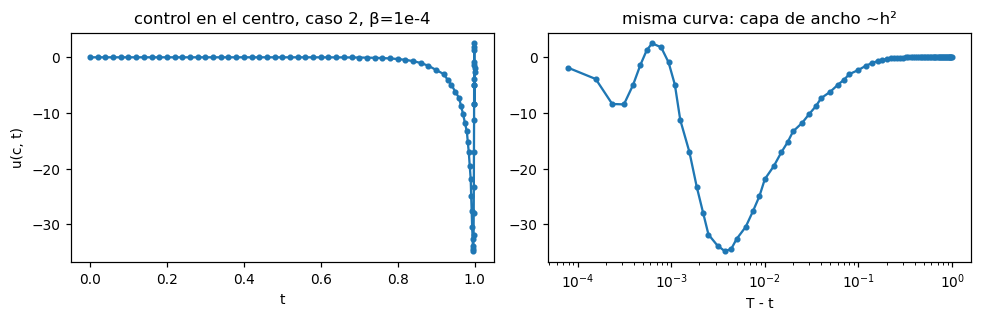

In [5]:
dd = C.FEM2(40)
print(f"{'malla temporal':28s} {'pasos':>5s} | {'β=1e-2':>9s} {'1e-3':>9s} {'1e-4':>9s}")
for lbl, t in [("uniforme Δt=1/50", C.time_grid(50)), ("uniforme Δt=1/400", C.time_grid(400)),
               ("graduada Δt0=1/50, K=8", C.time_grid(50, 8)), ("graduada Δt0=1/200, K=8", C.time_grid(200, 8))]:
    vals = []
    for b in CB.BETAS:
        o, U, _ = CB.solve(dd, 2, b, t)
        vals.append(o.J(U))
    print(f"{lbl:28s} {len(t) - 1:5d} | {vals[0]:9.5g} {vals[1]:9.5g} {vals[2]:9.5g}")

o, U, _ = CB.solve(dd, 2, 1e-4, C.time_grid(50, 8))
ic = np.argmin(np.sum((dd.P - 0.5) ** 2, 1))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(o.t, U[:, ic], ".-"); ax[0].set(xlabel="t", ylabel="u(c, t)", title="control en el centro, caso 2, β=1e-4")
ax[1].semilogx(1 - o.t[:-1], U[:-1, ic], ".-"); ax[1].set(xlabel="T - t", title="misma curva: capa de ancho ~h²")
plt.tight_layout(); plt.show()

Esto explica también la gran diferencia del libro entre sus mallas en el caso 2 (0.0019 → 0.0050 con $\beta=10^{-4}$):
con $\Delta t=0.05$ la capa no está resuelta. Es un fenómeno a vigilar en la tesis si el funcional incluye la
concentración al tiempo final.

## 5. Referencia y benchmark

Referencia: FEM con blanco exacto, CN, $n=20,40,80$ con $\Delta t_0=1/(5n)$ (caso 2 graduado hasta
$\Delta t_{\min}\lesssim h^2/10$) y Richardson. Nivel rápido: RBF-FD y FEM en $n=20$ contra la referencia, con evaluación
cruzada del control RBF-FD en el FEM.

In [6]:
ref = json.loads(CB.REF.read_text())
for case, e in ref["casos"].items():
    for b, v in e.items():
        print(f"caso {case} β={b:>6s}: J* = {v['valor']:.7g} ± {v['error_estimado_n80']:.1e}  (orden {v['orden']:.2f},"
              f" niveles {np.round(v['niveles'], 7)})")
t0 = time.time()
r = CB.nivel(20, ref)
f = CB.verificar(r, ref)
print("\nRESULTADO:", "OK" if not f else f, f"({time.time() - t0:.0f}s)")

caso 1 β=  0.01: J* = 184.0845 ± 1.4e-02  (orden 1.97, niveles [184.2972281 184.138893  184.0984322])
caso 1 β= 0.001: J* = 126.9785 ± 3.2e-02  (orden 1.95, niveles [127.466019  127.104281  127.0109366])
caso 1 β=0.0001: J* = 87.40302 ± 7.1e-02  (orden 1.94, niveles [88.4458202 87.674865  87.4738849])
caso 2 β=  0.01: J* = 0.02564508 ± 1.7e-05  (orden 1.87, niveles [0.0258679 0.025706  0.0256618])
caso 2 β= 0.001: J* = 0.0114678 ± 4.6e-05  (orden 1.90, niveles [0.0121065 0.0116384 0.0115134])
caso 2 β=0.0001: J* = 0.003897633 ± 1.6e-04  (orden 1.68, niveles [0.0055378 0.0044081 0.0040565])

n = 20: 441 nodos
caso      β |     J*_ref |     J*_RBF   err%  it |     J*_FEM   err% | J_FEM(û_RBF)     Δ% |    s


   1  1e-02 |    184.085 |    184.226   0.08   5 |    184.297   0.12 |        184.3   0.00 |  0.5


   1  1e-03 |    126.978 |    127.625   0.51  11 |    127.466   0.38 |      127.477   0.01 |  0.9


   1  1e-04 |     87.403 |    88.8969   1.71  22 |    88.4458   1.19 |      88.5044   0.07 |  1.4


   2  1e-02 |  0.0256451 |  0.0260625   1.63   7 |  0.0258679   0.87 |    0.0258985   0.12 |  0.8


   2  1e-03 |  0.0114678 |  0.0132214  15.29  16 |  0.0121065   5.57 |    0.0123328   1.87 |  1.3


   2  1e-04 | 0.00389763 | 0.00790231 102.75  31 | 0.00553776  42.08 |   0.00618418  11.67 |  2.1

RESULTADO: OK (7s)


## 6. Conclusiones

**Comparación final** (`python3 calor_benchmark.py --libro`):

| caso | β | libro (i) | nodal $n=25$, $\Delta t=0.05$ | libro (ii) | nodal $n=45$, $\Delta t=0.01$ | referencia (blanco exacto) |
|---|---|---|---|---|---|---|
| 1 | 1e-2 | 147.66 | 141.67 | 159.56 | 160.96 | 184.08 ± 0.01 |
| 1 | 1e-3 | 91.913 | 101.93 | 104.94 | 113.51 | 126.98 ± 0.03 |
| 1 | 1e-4 | 55.412 | 72.781 | 67.215 | 79.583 | 87.40 ± 0.07 |
| 2 | 1e-2 | 0.018837 | 0.022204 | 0.022603 | 0.023382 | 0.025645 |
| 2 | 1e-3 | 0.0074174 | 0.013930 | 0.012369 | 0.011916 | 0.011468 |
| 2 | 1e-4 | 0.0019042 | 0.0066353 | 0.0050182 | 0.0049098 | 0.00390 ± 4 % |

1. **Las soluciones óptimas coinciden con las del libro**: rangos y formas del estado y del control (Figs. 8.1–8.2).
2. **Los valores de $J$ son consistentes con el libro en la malla (ii)** cuando se evalúa $J_h$ igual que él (blanco
   interpolado en los nodos, ec. 8.12): 0.9 % en el caso 1 con $\beta=10^{-2}$, 1–4 % en todo el caso 2. Para $\beta$
   pequeño en el caso 1 la diferencia (8–18 %) es del tamaño de la propia variación del libro entre sus mallas: con
   un blanco discontinuo, $J_h$ depende de cómo cada malla interpola la cruz.
3. **La malla (i) del libro no está resuelta**: sus valores difieren de los de (ii) entre 8 % y 2.6×, y en el caso 2
   $\Delta t=0.05$ no resuelve la capa límite del control en $t=T$.
4. **Los valores del libro no son valores del problema continuo.** Con el blanco integrado exactamente y la malla
   convergida, $J^*$ es mayor: 184.08 / 126.98 / 87.40 (caso 1) y 0.02565 / 0.01147 / 0.0039 (caso 2). Esa es
   nuestra referencia.
5. **Método:** RBF-FD y FEM coinciden (caso 1: 0.1–1.7 % ya en $n=20$; la evaluación cruzada $J_{FEM}(\hat u_{RBF})$
   queda a <0.1 %). En el caso 2 con $\beta$ pequeño $n=20$ es preasintótica para los dos métodos (blanco final discontinuo): RBF-FD da un $J$ mayor que el FEM, pero su control evaluado en el FEM queda a 2–12 % del óptimo, sin óptimo espurio. CG necesita 5–33 iteraciones frente a 36–318 del BFGS del libro (criterios de parada distintos,
   pero la diferencia es de un orden de magnitud y crece con $1/\beta$ igual que en el libro).
6. **Lección para la tesis:** si el funcional observa el estado **al tiempo final** con un blanco poco suave, el
   control tiene una capa límite en $t=T$ que el paso uniforme no resuelve; hay que graduar $\Delta t$ hacia $T$ (o
   verificar convergencia en $\Delta t$ del óptimo, no sólo del estado).